# Decision-tree discretisation with Feature-engine

This notebook follows the linked Feature-engine example using the local Ames-style housing data (`housing.csv`). Decision-tree discretisation converts continuous measurements into a small number of intervals chosen with the help of the target variable.

We use `area` and `bedrooms` as predictors and `price` as the regression target. The notebook demonstrates interval boundaries, integer bin numbers, and tree predictions.

## What the transformer does

For each selected numeric feature, `DecisionTreeDiscretiser` trains a separate decision-tree regressor. The tree searches for cut points that make target values within each leaf as similar as possible. Those cut points become bin boundaries.

This is supervised discretisation: `price` is needed while fitting. Test targets must not be used to learn the boundaries. The result is useful when a model benefits from finite, simpler feature values or when a relationship is easier to explain as ranges.

In [1]:
# Install missing packages into the active Jupyter kernel. This keeps the notebook self-contained.
import importlib.util
import subprocess
import sys
required_packages = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "seaborn": "seaborn", "sklearn": "scikit-learn", "feature_engine": "feature-engine"}
missing_packages = [package for module, package in required_packages.items() if importlib.util.find_spec(module) is None]
if missing_packages:
    print("Installing missing packages:", missing_packages)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing_packages])

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.tree import plot_tree
from feature_engine.discretisation import DecisionTreeDiscretiser
sns.set_theme(style="whitegrid", context="notebook")

## 1. Load and inspect the data

The notebook is in `feature-engineering/discretisation`, while the project copy of `housing.csv` is in `feature-engineering/encoding`. The path search allows execution from either the project root or the notebook folder.

In [2]:
candidate_paths = [Path("housing.csv"), Path("../encoding/housing.csv"), Path("feature-engineering/encoding/housing.csv")]
data_path = next((p for p in candidate_paths if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("Could not find housing.csv. Place it in feature-engineering/encoding/.")
data = pd.read_csv(data_path)
for col in ["area", "bedrooms", "price"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")
data = data.dropna(subset=["area", "bedrooms", "price"]).reset_index(drop=True)
print(f"Loaded {data_path} with {len(data):,} complete rows.")
display(data.head())
display(data[["area", "bedrooms", "price"]].describe().round(2))
display(data.isna().sum().rename("missing_count").to_frame())

Loaded ../encoding/housing.csv with 545 complete rows.


,area,bedrooms,price
0,7420,4,13300000
1,8960,4,12250000
2,9960,3,12250000
3,7500,4,12215000
4,7420,4,11410000


,area,bedrooms,price
count,545.00,545.00,545.00
mean,5150.54,2.97,4766729.25
std,2170.14,0.74,1870439.62
min,1650.00,1.00,1750000.00
25%,3600.00,2.00,3430000.00
50%,4600.00,3.00,4340000.00
75%,6360.00,3.00,5740000.00
max,16200.00,6.00,13300000.00


,missing_count
area,0
bedrooms,0
price,0


## 2. Explore the raw continuous features

The distributions show the original measurements before discretisation. The scatter plots show how each feature relates to price. Skew or outliers can make a few interpretable ranges useful for some models.

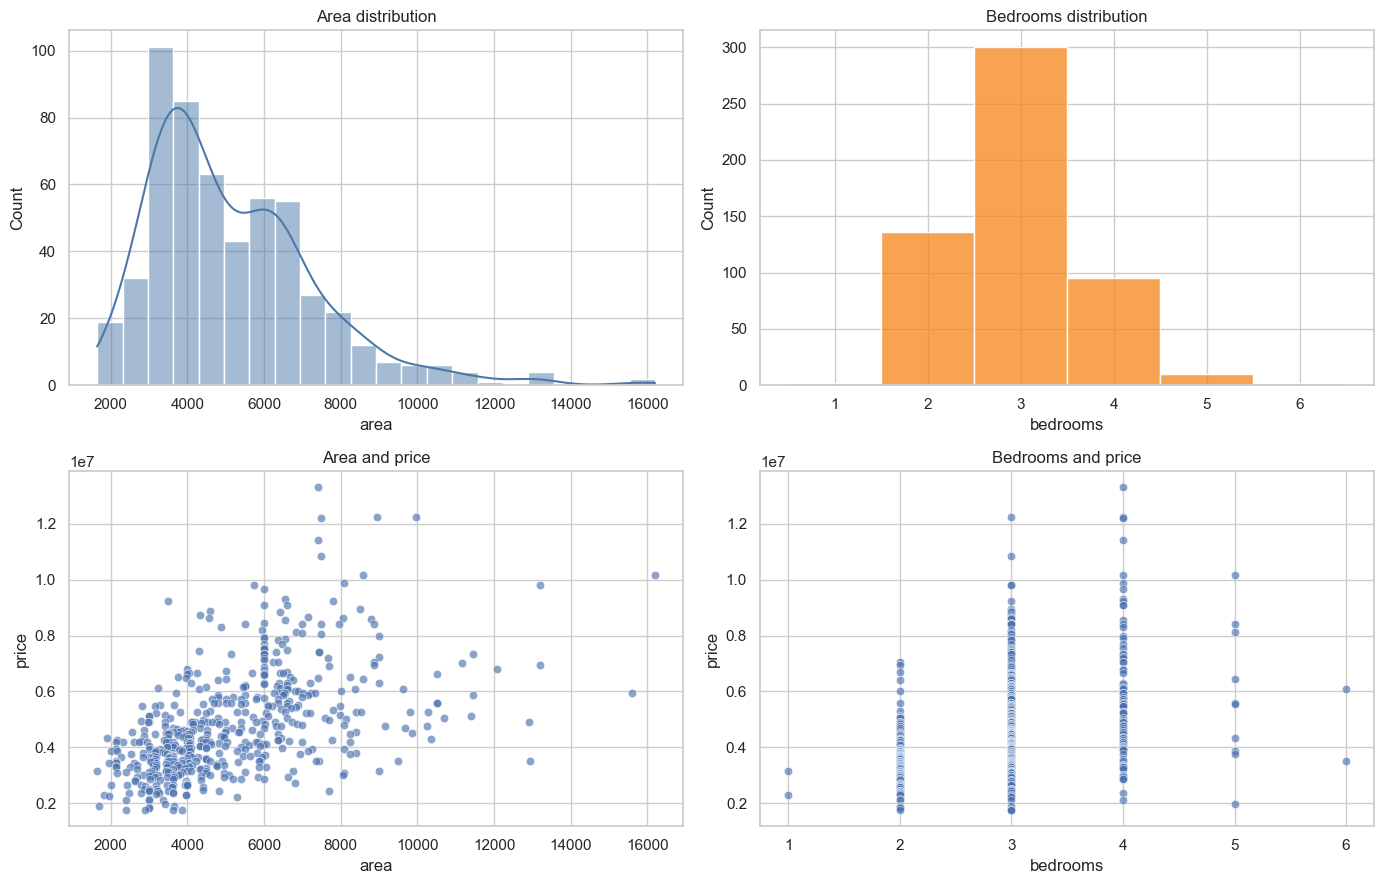

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
sns.histplot(data=data, x="area", kde=True, color="#4C78A8", ax=axes[0, 0])
axes[0, 0].set_title("Area distribution")
sns.histplot(data=data, x="bedrooms", discrete=True, color="#F58518", ax=axes[0, 1])
axes[0, 1].set_title("Bedrooms distribution")
sns.scatterplot(data=data, x="area", y="price", alpha=0.65, ax=axes[1, 0])
axes[1, 0].set_title("Area and price")
sns.scatterplot(data=data, x="bedrooms", y="price", alpha=0.65, ax=axes[1, 1])
axes[1, 1].set_title("Bedrooms and price")
plt.tight_layout(); plt.show()

## 3. Split before fitting

The boundary search is learned from the training set only. This prevents held-out houses from influencing preprocessing.

In [4]:
features = ["area", "bedrooms"]
X = data[features].copy(); y = data["price"].copy()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=0)
print("Training shape:", X_train.shape, "Test shape:", X_test.shape)

Training shape: (381, 2) Test shape: (164, 2)


## 4. Fit target-informed intervals

The transformer trains one regression tree per feature. The explicit depth grid tests shallow trees through depth 4 using three-fold cross-validation and negative mean squared error. A shallow tree produces broad bins; deeper trees capture detail but can overfit.

In [6]:
discretiser = DecisionTreeDiscretiser(variables=features, bin_output="boundaries", precision=2, cv=3, scoring="neg_mean_squared_error", param_grid={"max_depth": [1, 2, 3, 4]}, regression=True, random_state=42)
discretiser.fit(X_train, y_train)
print("Learned boundaries:")
for feature, boundaries in discretiser.binner_dict_.items(): print(feature, boundaries)
display(pd.Series(discretiser.scores_dict_, name="training_score"))

Learned boundaries:
area [-inf, np.float64(3385.0), np.float64(3995.0), np.float64(4515.0), np.float64(5954.0), np.float64(7415.0), np.float64(7965.0), np.float64(8311.0), inf]
bedrooms [-inf, np.float64(1.5), np.float64(2.5), np.float64(3.5), inf]


area       -2.051360e+12
bedrooms   -2.954931e+12
Name: training_score, dtype: float64

## 5. Readable boundary output

With `bin_output="boundaries"`, every value becomes an interval label. This is useful for reporting and for checking whether the learned ranges make business sense.

In [7]:
X_train_boundaries = discretiser.transform(X_train)
X_test_boundaries = discretiser.transform(X_test)
display(X_train_boundaries.head(10))
for feature in features:
    display(X_train_boundaries[feature].value_counts().sort_index().rename("count").to_frame())

,area,bedrooms
454,"(3995.0, 4515.0]","(2.5, 3.5]"
392,"(3385.0, 3995.0]","(2.5, 3.5]"
231,"(3995.0, 4515.0]","(2.5, 3.5]"
271,"(-inf, 3385.0]","(3.5, inf]"
250,"(3385.0, 3995.0]","(2.5, 3.5]"
541,"(-inf, 3385.0]","(2.5, 3.5]"
461,"(4515.0, 5954.0]","(1.5, 2.5]"
124,"(5954.0, 7415.0]","(2.5, 3.5]"
154,"(3385.0, 3995.0]","(2.5, 3.5]"
451,"(5954.0, 7415.0]","(1.5, 2.5]"


,count
area,
"(-inf, 3385.0]",67
"(3385.0, 3995.0]",69
"(3995.0, 4515.0]",53
"(4515.0, 5954.0]",68
"(5954.0, 7415.0]",80
"(7415.0, 7965.0]",13
"(7965.0, 8311.0]",11
"(8311.0, inf]",20


,count
bedrooms,
"(-inf, 1.5]",1
"(1.5, 2.5]",97
"(2.5, 3.5]",211
"(3.5, inf]",72


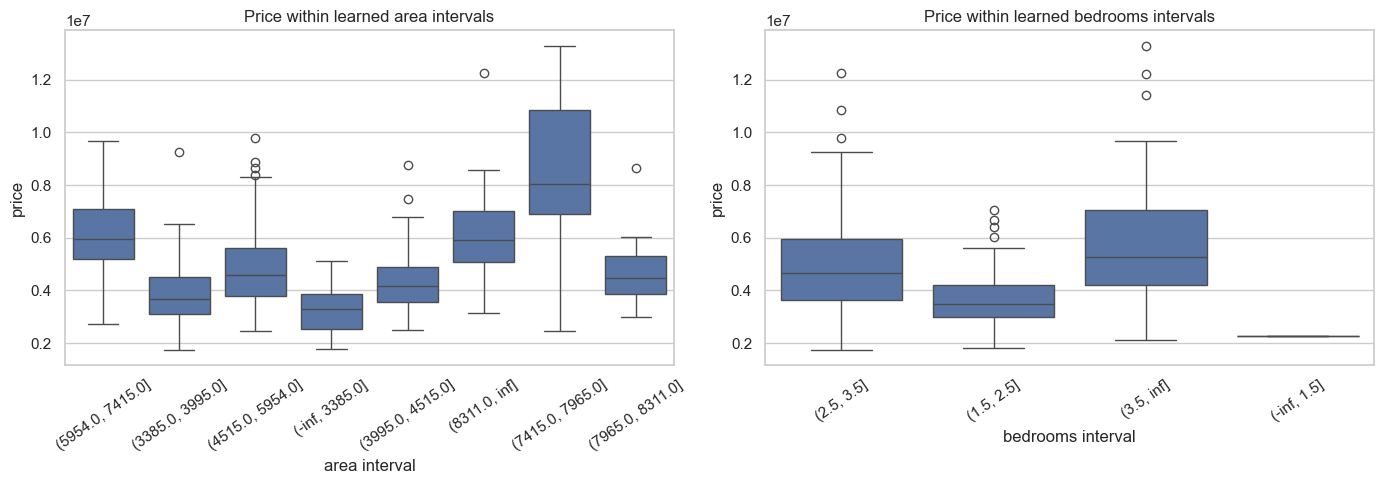

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, feature in zip(axes, features):
    plot_data = pd.DataFrame({feature: X_train[feature], "price": y_train, "bin": X_train_boundaries[feature].astype(str)})
    order = X_train_boundaries[feature].value_counts().index.tolist()
    sns.boxplot(data=plot_data, x="bin", y="price", order=order, ax=ax)
    ax.set_title(f"Price within learned {feature} intervals"); ax.set_xlabel(feature + " interval"); ax.tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()

## 6. Integer bins and tree predictions

`bin_number` gives compact numeric labels beginning at zero. `prediction` gives each row the regression prediction of its tree leaf. All rows in the same leaf receive the same finite value.

In [11]:
number_discretiser = DecisionTreeDiscretiser(variables=features, bin_output="bin_number", cv=3, scoring="neg_mean_squared_error", param_grid={"max_depth": [1, 2, 3, 4]}, regression=True, random_state=42)
number_discretiser.fit(X_train, y_train)
X_train_bins = number_discretiser.transform(X_train); X_test_bins = number_discretiser.transform(X_test)
display(pd.concat([X_train.head(8), X_train_bins.add_suffix("_bin").head(8)], axis=1))
for feature, boundaries in number_discretiser.binner_dict_.items(): print(feature, boundaries)

,area,bedrooms,area_bin,bedrooms_bin
454,4500,3,2,2
392,3990,3,1,2
231,4320,3,2,2
271,1905,5,0,3
250,3510,3,1,2
541,2400,3,0,2
461,4960,2,3,1
124,6525,3,4,2


area [-inf, np.float64(3385.0), np.float64(3995.0), np.float64(4515.0), np.float64(5954.0), np.float64(7415.0), np.float64(7965.0), np.float64(8311.0), inf]
bedrooms [-inf, np.float64(1.5), np.float64(2.5), np.float64(3.5), inf]


In [15]:
# Feature-engine requires precision to be None or a positive integer.
# Use one decimal place here; round to whole currency units afterward if desired.
prediction_discretiser = DecisionTreeDiscretiser(variables=features, bin_output="prediction", precision=1, cv=3, scoring="neg_mean_squared_error", param_grid={"max_depth": [1, 2, 3, 4]}, regression=True, random_state=42)
prediction_discretiser.fit(X_train, y_train)
X_train_predictions = prediction_discretiser.transform(X_train); X_test_predictions = prediction_discretiser.transform(X_test)
display(pd.concat([X_train.head(8), X_train_predictions.add_suffix("_tree_prediction").head(8)], axis=1))

,area,bedrooms,area_tree_prediction,bedrooms_tree_prediction
454,4500,3,4372688.7,4984329.1
392,3990,3,3863594.2,4984329.1
231,4320,3,4372688.7,4984329.1
271,1905,5,3258761.2,5715500.0
250,3510,3,3863594.2,4984329.1
541,2400,3,3258761.2,4984329.1
461,4960,2,4872154.4,3620299.0
124,6525,3,6056305.5,4984329.1


## 7. Inspect the learned trees

Each feature receives its own one-variable tree. The diagrams make the thresholds and leaf predictions visible.

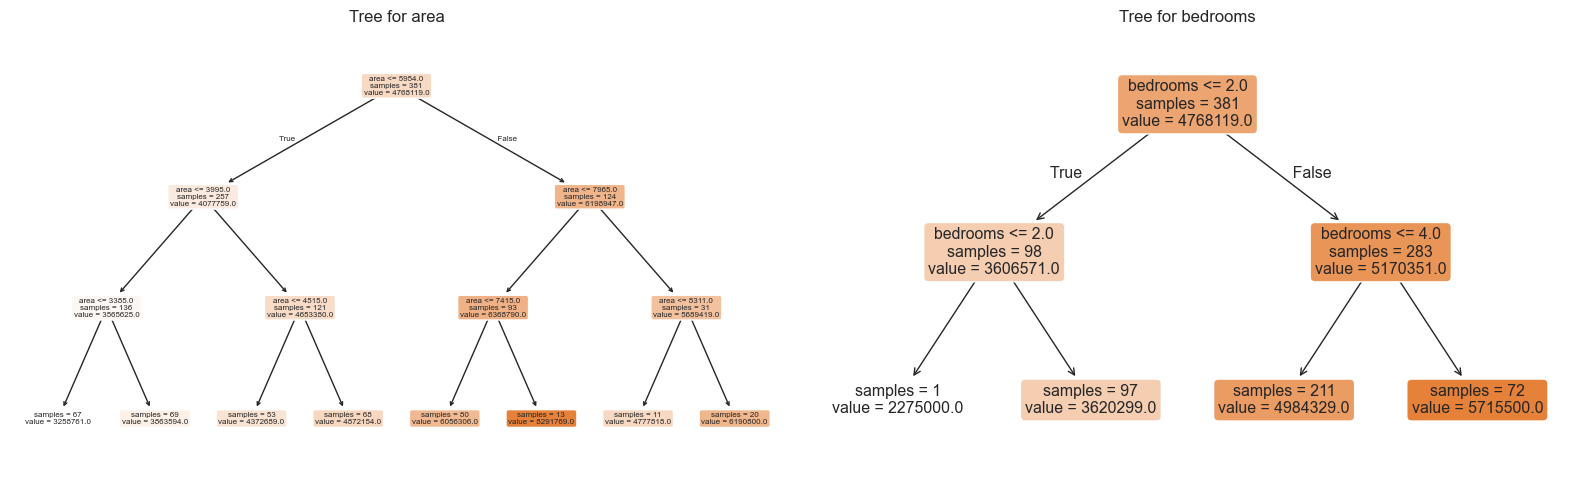

In [16]:
fig, axes = plt.subplots(1, len(features), figsize=(16, 5))
if len(features) == 1: axes = [axes]
for ax, feature in zip(axes, features):
    best_tree = prediction_discretiser.binner_dict_[feature].best_estimator_
    plot_tree(best_tree, feature_names=[feature], filled=True, rounded=True, impurity=False, precision=0, ax=ax)
    ax.set_title(f"Tree for {feature}")
plt.tight_layout(); plt.show()

## 8. Compare raw and discretised linear models

A linear model on the raw variables assumes one straight-line effect per feature. A linear model on tree predictions uses target-informed finite summaries. This comparison is illustrative; it is not a replacement for repeated cross-validation.

In [17]:
raw_model = LinearRegression().fit(X_train, y_train)
raw_pred = raw_model.predict(X_test)
tree_model = LinearRegression().fit(X_train_predictions[features], y_train)
tree_pred = tree_model.predict(X_test_predictions[features])
comparison = pd.DataFrame({
    "model inputs": ["Raw area + bedrooms", "Decision-tree predictions"],
    "MAE": [mean_absolute_error(y_test, raw_pred), mean_absolute_error(y_test, tree_pred)],
    "R2": [r2_score(y_test, raw_pred), r2_score(y_test, tree_pred)],
})
display(comparison.round(3))

,model inputs,MAE,R2
0,Raw area + bedrooms,1106604.232,0.381
1,Decision-tree predictions,1090060.079,0.375


## 9. Validate the transformation and note limitations

The test set is transformed using boundaries learned from training rows. Decision-tree discretisation can overfit if trees are too deep, so cross-validation and a restrained parameter grid matter. Binning also discards within-bin detail and can make predictions change abruptly near a learned threshold.

For production use, place the discretiser inside a scikit-learn pipeline and fit it separately inside each cross-validation training fold. Compare it against simpler equal-width, equal-frequency, and domain-defined bins.

In [18]:
assert len(X_train_boundaries) == len(X_train)
assert len(X_test_boundaries) == len(X_test)
assert set(X_train_bins[features].stack().dropna().unique()) <= set(range(20))
print("Checks passed.")
display(pd.DataFrame({
    "feature": features,
    "number_of_bins": [X_train_boundaries[c].nunique() for c in features],
    "training_min": [X_train[c].min() for c in features],
    "training_max": [X_train[c].max() for c in features],
}))

Checks passed.


,feature,number_of_bins,training_min,training_max
0,area,8,1836,15600
1,bedrooms,4,1,5


## Summary

`DecisionTreeDiscretiser` learns one regression tree per numeric feature, tunes tree depth by cross-validation, and converts continuous values into target-informed finite regions. Use `boundaries` for explanation, `bin_number` for compact numeric categories, and `prediction` when leaf target summaries are useful as model inputs. Always fit it on training data only and tune complexity to control overfitting.